# <b>BTC.</b>

# <b>Problem Statement.</b>

We solve the problem of building a toxic trade filter. For each trade, we observe market features $X_i$, trade weight $w_i$, and the realized maker PnL over a selected horizon $t$, for example $30s$:

The model's task is to predict the expected PnL from the trade features:
$\hat y_i = f(X_i).$

On the calibration set, we tune the threshold. For each possible threshold value, we construct a binary filter:

$
a_i =
\begin{cases}
1, & toxicity_i > threshold, \\
0, & toxicity_i \le threshold.
\end{cases}
$

The threshold is selected **only on the calibration set**. The objective is to maximize the Score under a constraint on the minimum remaining turnover:
$Score = PnL_{kept} - PnL_{all}.$


## <b>Schematic.</b>

```text
Features X
   ↓
Regression model on train
   ↓
Predicted PnL
   ↓
Toxicity = - Predicted PnL
   ↓
Threshold tuning on calib
   ↓
Embargo
   ↓
Final OOS test evaluation

## <b>Imports.</b>

In [ ]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd() / "src"))

from experiment import (
    WalkForwardConfig,
    walk_forward
)
from features import get_feature_set
from splits import get_window_ids

import utilities as util

In [2]:
import warnings

warnings.filterwarnings(
    "ignore",
    message=r"X does not have valid feature names, but LGBMRegressor was fitted with feature names",
    category=UserWarning
)
warnings.filterwarnings("ignore", category=UserWarning, module="matplotlib")

## <b>Config.</b>

In [3]:
INSTRUMENT = "btc"                    # "btc" or "eth"
MODEL_NAME = "lgbm_huber"
HORIZONS   = [30, 120, 300]

MAX_FILTER_RATES = [0.99, 0.995, 0.999]
FOCUS_FILTER_RATE = 0.999             # used for per-trade histograms

SPLIT_DIR = Path(f"data/meta/{INSTRUMENT}_splits_only")

BASE_FEATURES = get_feature_set("advanced", horizons_s=HORIZONS)
print(f"Base features ({len(BASE_FEATURES)}): {BASE_FEATURES}")

Base features (40): ['spread', 'obi', 'dist_to_mid', 'hour', 'vpin_5s', 'vpin_30s', 'vpin_120s', 'rv_5s', 'rv_30s', 'rv_120s', 'liq_binance_5s', 'liq_binance_30s', 'liq_binance_120s', 'liq_bybit_5s', 'liq_bybit_30s', 'liq_bybit_120s', 'log_notional', 'net_liq_5s', 'net_liq_30s', 'net_liq_120s', 'liq_agreement_30s', 'signed_dist_to_mid', 'signed_obi', 'signed_liq_binance_5s', 'signed_liq_binance_30s', 'signed_liq_binance_120s', 'signed_liq_bybit_5s', 'signed_liq_bybit_30s', 'signed_liq_bybit_120s', 'vpin_ratio_5_120', 'rv_ratio_5_120', 'liq_binance_ratio_5_120', 'liq_bybit_ratio_5_120', 'dist_to_mid_over_spread', 'notional_over_median', 'liq_aligned_5s', 'liq_aligned_30s', 'liq_aligned_120s', 'liq_direction_agreement_30s', 'liq_accel_5_30']


## <b>1. Walk-Forward.</b>

| window | train | embargo | test |
|---|---|---|---|
| W1 | 2025-11-01 .. 11-30 | 12-01 .. 12-07 | 2025-12-08 .. 12-31 |
| W2 | 2025-11-01 .. 12-31 | 01-01 .. 01-07 | 2026-01-08 .. 01-31 |
| W3 | 2025-11-01 .. 01-31 | 02-01 .. 02-07 | 2026-02-08 .. 02-28 |
| W4 | 2025-11-01 .. 02-28 | 03-01 .. 03-07 | 2026-03-08 .. 03-31 |
| W5 | 2025-11-01 .. 03-31 | 04-01 .. 04-07 | 2026-04-08 .. 04-28 |

Walk-forward validation is used to check the quality of the filter. Each window consists of three parts:

1. `train_model` - the subset of data used to train the PnL model;
2. `calib` - the portion of the data used to determine the toxicity threshold;
3. `test` - the fully validated out-of-sample portion, on which the final metrics are calculated.

In [4]:
# Dictionary of WalkForwardResult objects.
results: dict[tuple[str, int], object] = {}

for tau in HORIZONS:

    config = WalkForwardConfig(
            instrument       = INSTRUMENT,
            tau              = tau,
            model_name       = MODEL_NAME,
            max_filter_rates = MAX_FILTER_RATES,
            window_ids       = get_window_ids(),
            verbose          = False,
            use_tqdm         = True
        )

    results[("base", tau)] = walk_forward(
            config     = config,
            features   = BASE_FEATURES,
            split_dir  = SPLIT_DIR
        )

WF btc lgbm_huber tau=30s:   0%|          | 0/5 [00:00<?, ?it/s]

WF btc lgbm_huber tau=120s:   0%|          | 0/5 [00:00<?, ?it/s]

WF btc lgbm_huber tau=300s:   0%|          | 0/5 [00:00<?, ?it/s]

## <b>2.Summary table.</b>

In [5]:
summary_table = util.build_wf_summary_table(
    results         = results,
    max_filter_rate = FOCUS_FILTER_RATE
)

summary_table

,variant,tau,window,max_filter_rate,pnl_all,pnl_kept,pnl_filtered,score,"kept_turnover_per_day, mln$",turnover_ok,filter_rate
0,base,30,W1,0.999,-0.102400,4.725100,-0.181278,4.827500,4.21,True,0.9921
1,base,30,W2,0.999,-0.106321,3.793907,-0.209654,3.900228,7.15,True,0.9854
2,base,30,W3,0.999,-0.157706,8.765269,-0.196868,8.922975,1.28,True,0.9980
3,base,30,W4,0.999,-0.157633,-13.908188,-0.025047,-13.750555,2.86,True,0.9953
4,base,30,W5,0.999,-0.085905,1.135743,-0.185016,1.221648,18.58,True,0.9538
5,base,120,W1,0.999,0.001451,5.124374,-0.045769,5.122922,2.39,True,0.9946
6,base,120,W2,0.999,0.096189,23.349713,-0.352767,23.253523,5.25,True,0.9884
7,base,120,W3,0.999,-0.242931,17.351156,-0.276717,17.594087,0.56,True,0.9989
8,base,120,W4,0.999,-0.209618,-7.329703,-0.164245,-7.120085,1.90,True,0.9967
9,base,120,W5,0.999,0.050937,7.683595,-0.007237,7.632658,1.87,True,0.9958


## <b>3. Chart with scores.</b>

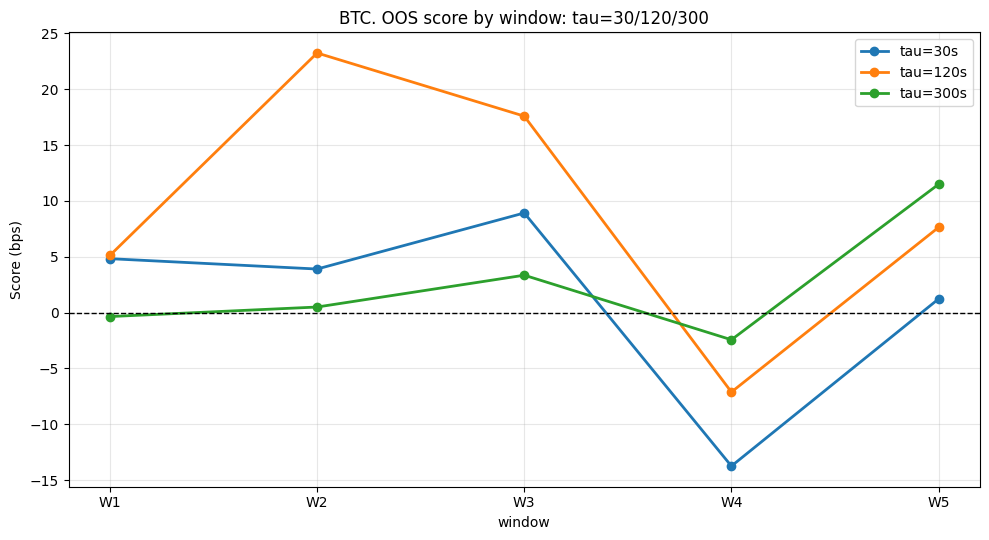

tau,30,120,300
window,,,
W1,4.827500,5.122922,-0.356887
W2,3.900228,23.253523,0.496901
W3,8.922975,17.594087,3.348166
W4,-13.750555,-7.120085,-2.436874
W5,1.221648,7.632658,11.491581


In [6]:
pivot_scores = util.plot_score_by_window_one_chart(
    summary_table       = summary_table,
    variant             = "base",
    taus                = (30, 120, 300),
    title               = "BTC. OOS score by window: tau=30/120/300"
)

pivot_scores

## <b>4. Distributions charts.</b>

BTC_lgbm_huber_base_tau120s_fr0.999
Daily Score:
  mean   = +7.986682
  std    = 15.980125
  median = +5.941315
  min    = -34.691805
  max    = +69.169228
  >0 days: 74/103 (72%)
  <0 days: 29/103 (28%)

BTC_lgbm_huber_base_tau120s_fr0.999
Daily PnL kept:
  mean   = +7.939187
  std    = 16.119438
  median = +5.814141
  min    = -36.831303
  max    = +68.897355
  >0 days: 74/103 (72%)
  <0 days: 29/103 (28%)



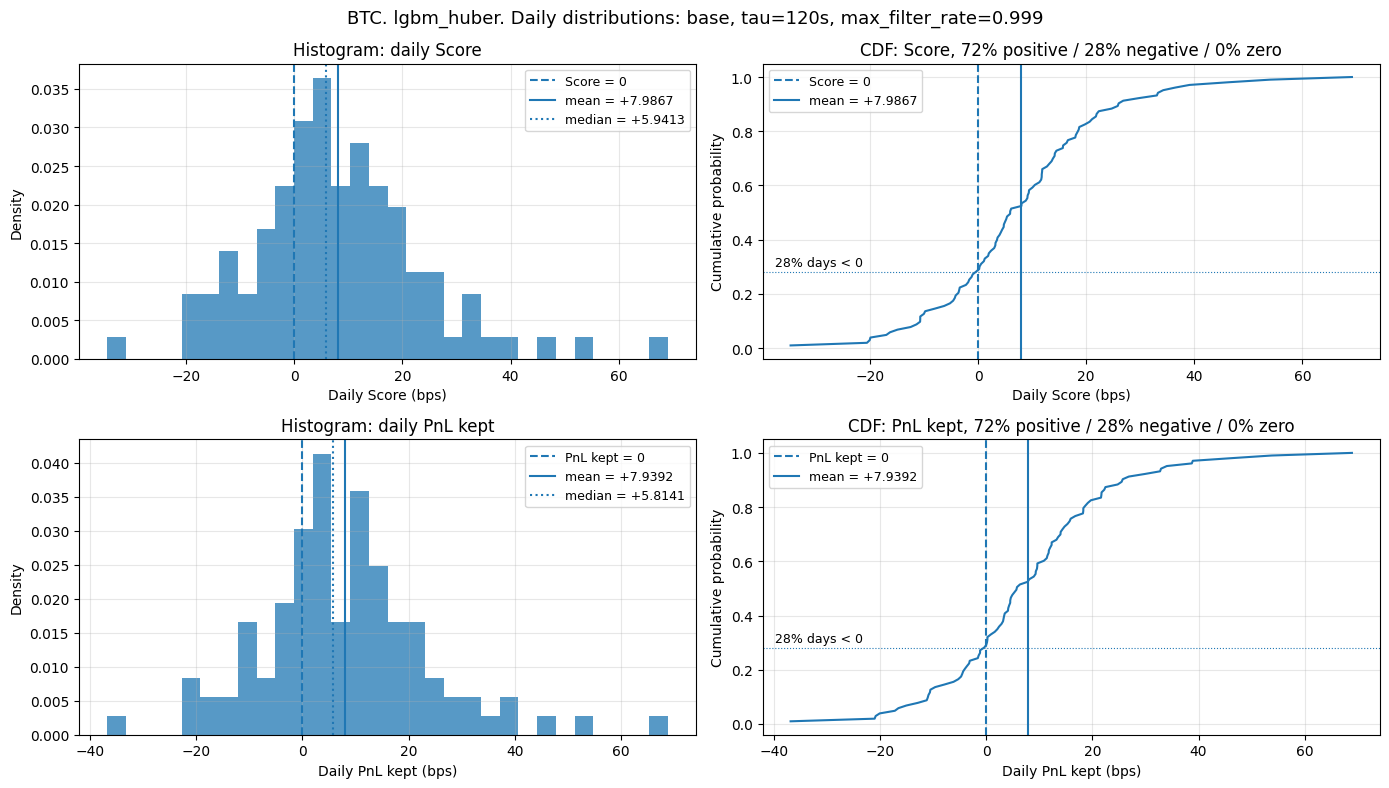

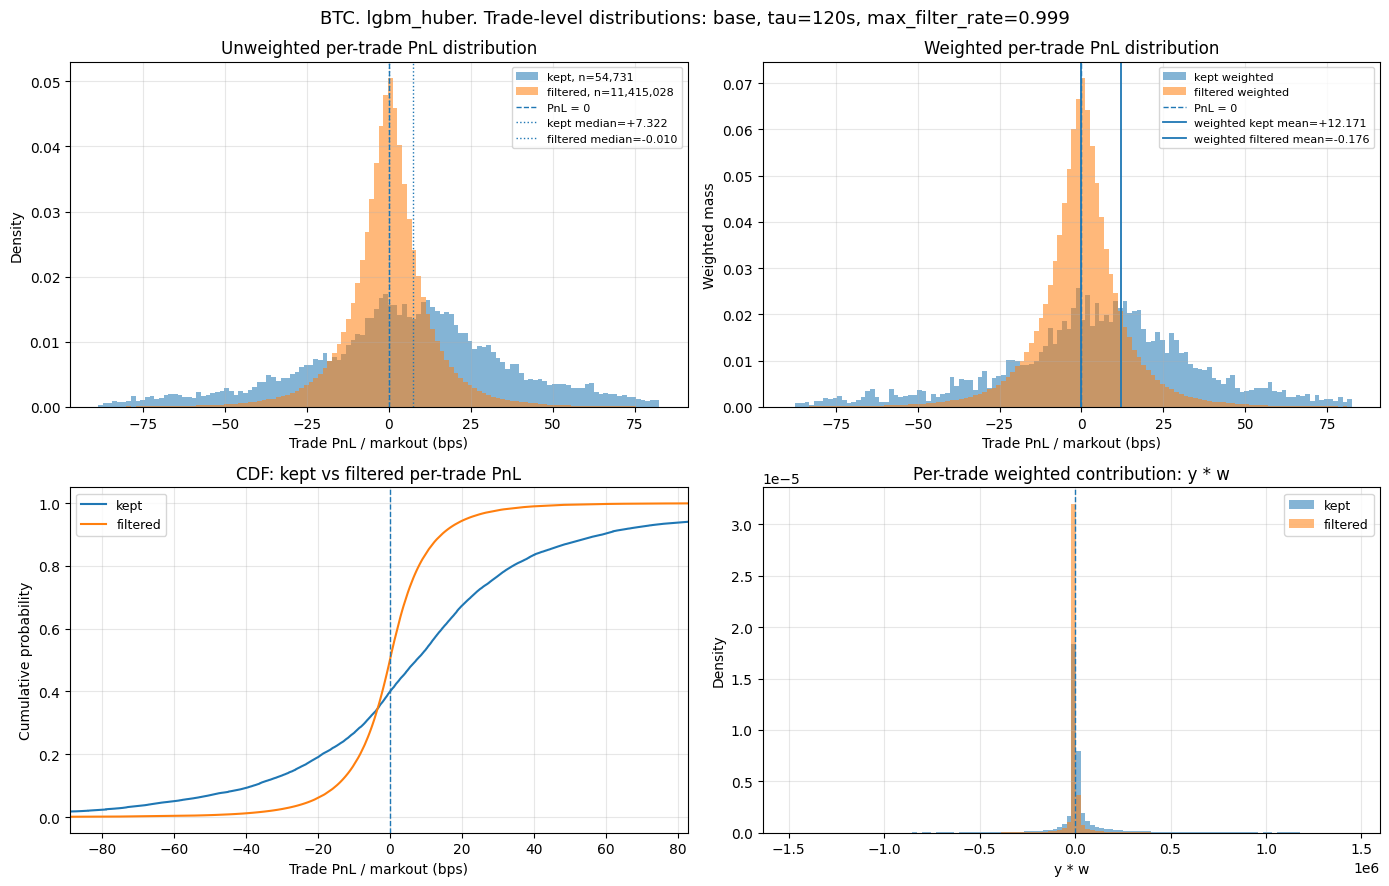

BTC | lgbm_huber | base | tau=120s | max_filter_rate=0.999
--------------------------------------------------------------------------------
n_all      = 11,469,759
n_kept     = 54,731 (0.48%)
n_filtered = 11,415,028 (99.52%)

Weighted PnL:
  pnl_all      = -0.066249 bps
  pnl_kept     = +12.170805 bps
  pnl_filtered = -0.176126 bps
  score        = +12.237054 bps

Unweighted per-trade PnL:
  all      mean=-0.176427, median=-0.001148, <0=50.0%
  kept     mean=+10.031551, median=+7.321504, <0=40.0%
  filtered mean=-0.225371, median=-0.010274, <0=50.1%


In [7]:
daily = util.plot_daily_score_distribution(
    results         = results,
    variant         = "base",
    tau             = 120,
    max_filter_rate = FOCUS_FILTER_RATE,
    instrument      = INSTRUMENT,
    model_name      = MODEL_NAME
)

trade = util.plot_per_trade_distribution(
    results         = results,
    variant         = "base",
    tau             = 120,
    max_filter_rate = FOCUS_FILTER_RATE,
    instrument      = INSTRUMENT,
    model_name      = MODEL_NAME
)


## <b>5. Feature importance.</b>

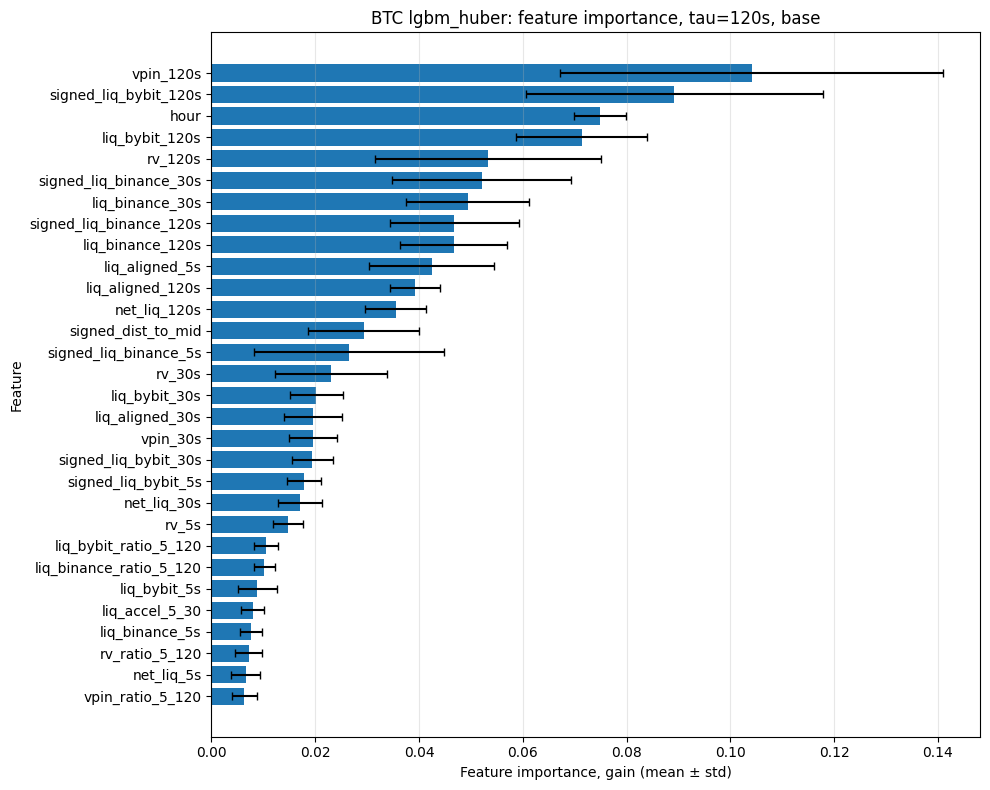

,feature,mean_importance,std_importance,n_models,sem_importance,interval
36,vpin_120s,0.104124,0.036941,5,0.016520,0.036941
31,signed_liq_bybit_120s,0.089187,0.028604,5,0.012792,0.028604
2,hour,0.074844,0.005014,5,0.002242,0.005014
12,liq_bybit_120s,0.071386,0.012603,5,0.005636,0.012603
23,rv_120s,0.053301,0.021717,5,0.009712,0.021717
29,signed_liq_binance_30s,0.052072,0.017187,5,0.007686,0.017187
9,liq_binance_30s,0.049379,0.011857,5,0.005303,0.011857
28,signed_liq_binance_120s,0.046821,0.012405,5,0.005548,0.012405
8,liq_binance_120s,0.046658,0.010253,5,0.004585,0.010253
7,liq_aligned_5s,0.042498,0.012054,5,0.005391,0.012054


In [8]:
tau = 120
variant = "base"

result = results[("base", tau)]

fi = util.plot_lgbm_feature_importance(
    models              = result.models,
    top_n              = 30,
    importance_type    = "gain",
    interval           = "std",
    normalize_per_model= True,
    figsize            = (10, 8),
    title              = f"{INSTRUMENT.upper()} {MODEL_NAME}: feature importance, tau={tau}s, {variant}"
)

display(fi.head(30))

---
## <b>Executive summary.</b>

On BTC, the best result was obtained for the horizon

$$
\tau = 120s.
$$

For the baseline `lgbm_huber` model with `max_filter_rate = 0.999`, this horizon yields the following out-of-sample score using walk-forward windows:

$$
W1: +5.12,\quad
W2: +23.25,\quad
W3: +17.59,\quad
W4: -7.12,\quad
W5: +7.63\ \text{bps}.
$$

The average score across the five windows is approximately

$$
+9.3\ \text{bps}.
$$

This is the best result among the three horizons for BTC. The model yields a positive score in four out of five walk-forward windows. The only negative window is `W4`, where the score drops to

$$
-7.12\ \text{bps}.
$$

Despite this, the `120s` horizon remains the primary BTC configuration, as it yields the highest average score and the strongest positive windows.

The `30s` horizon also yields a positive result in four out of five windows:

$$
W1: +4.83,\quad
W2: +3.90,\quad
W3: +8.92,\quad
W4: -13.75,\quad
W5: +1.22\ \text{bps}.
$$

The average Score for `30s` is approximately

$$
+1.0\ \text{bps}.
$$

However, the result over this time horizon is noticeably weaker and less stable. The main issue is a sharp negative dip in `W4`:

$$
W4: -13.75\ \text{bps}.
$$

Because of this, `30s` is not considered the primary time horizon for BTC.

The `300s` time frame shows a weaker picture:

$$
W1: -0.36,\quad
W2: +0.50,\quad
W3: +3.35,\quad
W4: -2.44,\quad
W5: +11.49\ \text{bps}.
$$

The average score for `300s` is approximately

$$
+2.5\ \text{bps}.
$$

This time horizon yields a positive result in only three out of five windows. Despite the strong result in `W5`, the overall stability is worse than that of `120s`.

The main conclusion for BTC: the strongest configuration is `lgbm_huber` with a horizon of

$$
\tau = 120s.
$$

It yields an average score of about

$$
+9.3\ \text{bps}
$$

and a positive result in most walk-forward windows.